# 01 Data QA — PVDAQ system 9069 (Simon Solar Farm, GA)

Goal of Phase 1: decide whether 9069 is usable, on which period and with which sensors, and produce a clean dataset. Configuration: `configs/system_9069.yaml`.

Sections:
1. Data coverage and sensor availability (full period, point sampling)
2. Clock and time zone: per-file clock rules, conversion to UTC, acceptance test
3. Geometry and sensors: clear-day profiles, measured vs modelled POA (fixed vs tracker), sensor agreement — *to be added*

In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
from pathlib import Path

# Run from the project root so that `src` imports and relative paths in the config work.
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
sys.path.insert(0, str(Path.cwd()))

import pandas as pd

from src import coverage as cv
from src.config import load_config
from src.plots import availability_heatmap

config = load_config("configs/system_9069.yaml")

## 1. Data coverage and sensor availability

**Method.** Point sampling instead of a full download: ~20 single-row reads per month per file via HTTP byte ranges (≈ 23 MB of traffic instead of ≈ 2.4 GB of CSV); each read returns a snapshot of all channels at one timestamp. Daylight = sun elevation > 15°, so that a 1-hour time-zone error cannot move a snapshot into the night. With ~9 daylight snapshots per month the availability estimate is accurate to about **±15 percentage points**.

Details: *valid* = not empty and not a logger placeholder (≤ −250, e.g. −297, −300). Gaps are found from time jumps between neighbouring snapshots; gaps shorter than ~3 days may be missed. Meter and irradiance files use stratified random offsets (a fixed step of ~25 h aliased with the daily cycle); electrical_ac and environment were sampled with a fixed step of ~32 h, which shifts the time of day by 8 h per snapshot and does not alias. All results below are read from the local cache (`data/processed/9069_coverage/`), no network access.

In [2]:
samples, gaps = cv.load_coverage(config)
table, n_daylight = cv.availability_table(samples, config)

months = pd.period_range("2016-02", "2023-11", freq="M")
table = table.reindex(columns=months)
table.index = [cv.short_label(c) for c in table.index]
n_daylight = n_daylight.reindex(months)
n_daylight.describe().round(1)

,electrical_ac,environment,irradiance,meter
count,90.0,89.0,91.0,78.0
mean,8.4,8.5,8.9,9.7
std,2.6,3.0,5.0,4.2
min,1.0,2.0,1.0,1.0
25%,7.0,7.0,4.5,7.0
50%,9.0,9.0,9.0,10.0
75%,10.0,11.0,13.0,12.0
max,14.0,15.0,24.0,20.0


Gaps longer than 1 day (no rows in the file):

In [3]:
gaps.sort_values(["last_before", "file"]).reset_index(drop=True).head(25)

,file,last_before,first_after,days
0,irradiance,2016-03-13 01:55:00,2016-03-15 11:45:00,2.4
1,meter,2016-04-28 07:15:00,2016-05-04 16:30:00,6.4
2,electrical_ac,2017-02-06 21:15:00,2017-05-13 07:30:00,95.4
3,environment,2017-02-06 21:15:00,2017-05-13 03:25:00,95.3
4,irradiance,2017-02-06 21:15:00,2017-05-13 03:25:00,95.3
5,meter,2017-02-06 21:15:00,2017-05-13 10:35:00,95.6
6,electrical_ac,2017-08-09 07:25:00,2017-08-18 21:00:00,9.6
7,environment,2017-08-09 07:25:00,2017-08-18 20:25:00,9.5
8,irradiance,2017-08-09 07:25:00,2017-08-18 20:25:00,9.5
9,meter,2017-08-09 07:25:00,2017-08-18 21:50:00,9.6


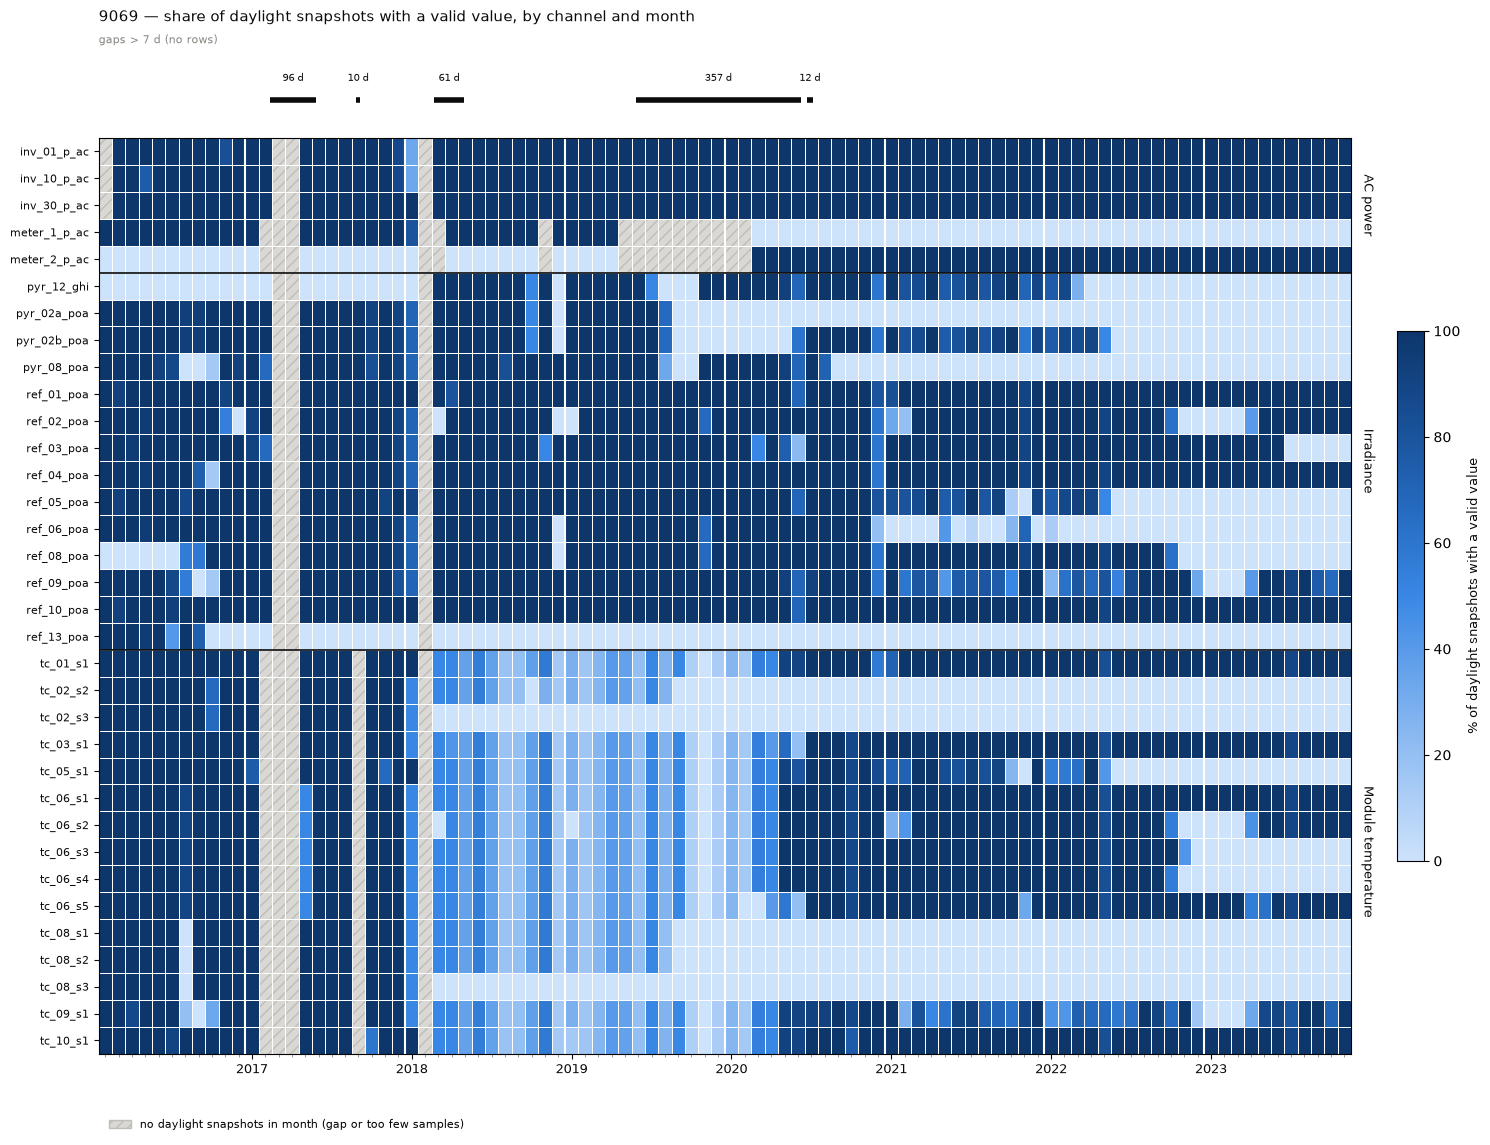

In [4]:
groups = [
    ("AC power", ["inv_01_p_ac", "inv_10_p_ac", "inv_30_p_ac", "meter_1_p_ac", "meter_2_p_ac"]),
    ("Irradiance", ["pyr_12_ghi"] + sorted(l for l in table.index if l.endswith("_poa"))),
    ("Module temperature", sorted(l for l in table.index if l.startswith("tc_"))),
]
fig = availability_heatmap(
    table, groups, gaps,
    title="9069 — share of daylight snapshots with a valid value, by channel and month",
)
Path("reports/figures").mkdir(parents=True, exist_ok=True)
fig.savefig("reports/figures/9069_data_coverage.png", dpi=130, bbox_inches="tight")

Yearly mean availability (%), for a compact overview:

In [5]:
table.T.groupby(table.columns.year).mean().T.round(0)

,2016,2017,2018,2019,2020,2021,2022,2023
inv_01_p_ac,98.0,99.0,94.0,100.0,100.0,100.0,100.0,100.0
inv_10_p_ac,98.0,99.0,94.0,100.0,100.0,100.0,100.0,100.0
inv_30_p_ac,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
tc_01_s1,100.0,100.0,43.0,26.0,74.0,98.0,99.0,99.0
tc_02_s2,97.0,100.0,33.0,20.0,0.0,0.0,0.0,0.0
tc_02_s3,97.0,100.0,5.0,0.0,0.0,0.0,0.0,0.0
tc_03_s1,100.0,100.0,38.0,26.0,67.0,100.0,99.0,99.0
tc_05_s1,100.0,93.0,43.0,26.0,74.0,75.0,27.0,0.0
tc_06_s1,99.0,94.0,39.0,26.0,78.0,100.0,99.0,99.0
tc_06_s2,99.0,94.0,34.0,24.0,78.0,89.0,78.0,67.0


### Observations

- **Gaps common to all files:** 2017-02-06 → 2017-05-13 (95 d), 2017-08-09 → 2017-08-18 (10 d), 2018-01-26 → 2018-03-28 (60 d).
- **Meter:** meter 1 reports 2016-02 … 2019-04, then a 357-day gap in the meter file (2019-04-04 → 2020-03-26); from 2020-03 only meter 2 reports. Whether both are the same plant revenue meter is an assumption, to be verified by magnitude.
- **Inverters 01 / 10 / 30:** close to 100 % outside the common gaps.
- **Module temperature:** all thermocouples are intermittent from 2018-03 to 2020-04 (same pattern on every sensor → likely a logger-level problem); from 2020-05 thermocouples 01, 03, 06 s1 and 10 are ≥ 90 %. Thermocouples 02 and 08 are dead from 2020.
- **POA:** reference cells 01, 04 and 10 are ≥ 90 % in almost every month. Class-A pyranometers (02A, 02B, 08) stop between 2020 and 2022; GHI (pyranometer 12) is missing in 2016–2017 and mostly in 2022–2023.
- Irradiance is logged at 15-min steps in 2019 (found in step 0), hence fewer snapshots.

Choice of the analysis period: pending (see candidates).

## 2. Clock and time zone (analysis period 2020-05 … 2023-11)

Timestamps in the PVDAQ files are naive; the metadata gives only `timezone_code: 5`. This is checked first, before geometry, because a clock error looks like an azimuth error.

**Method.** For every day and every channel that follows the sun, the day's 5-min profile is correlated with clear-sky GHI (pvlib, Haurwitz model) shifted by candidate offsets from UTC−6 to UTC−3 in 5-min steps; the offset with the highest correlation *r* is the day's clock offset (label − UTC). Haurwitz needs only the sun position, and correlation ignores amplitude, so the same test works for irradiance and for AC power. Only clear days (*r* > 0.97) are used for conclusions. The night-time jumps in the timestamp axis are **not** used: they fall on the same dates in every file, while the data content of the files follows different rules (below).

**Candidate rules.** UTC−5 in winter and UTC−4 in summer, with the switch on US dates (2nd Sunday of March, 1st Sunday of November; `America/New_York`) or on EU dates (last Sunday of March and of October, 01:00 UTC) — the EU hypothesis came from the switch windows in the GHI data.

In [6]:
from src import timealign as ta
from src.plots import clock_offset_plot

lat, lon = config["system"]["latitude"], config["system"]["longitude"]
clk = config["clock"]


def channel(file, col):
    """One column of the analysis period, on raw naive labels (nothing converted yet)."""
    return ta.load_period(config, file, [col])[col]


# One sun-following channel per file (environment: module temperature, used in the test below).
ref = channel("irradiance", clk["reference_channel"])
ghi = channel("irradiance", "ghi_pyr12_wm2")
inv01 = channel("electrical_ac", "p_ac_inv01_kw")
meter2 = channel("meter", "p_ac_meter2_kw")
tmod = channel("environment", "t_mod_tc01s1_c")

channels = {"POA ref cell 01": ref, "GHI pyranometer 12": ghi,
            "AC inverter 01": inv01, "AC meter 2": meter2}
offsets = {name: ta.daily_clock_offset(s, lat, lon, min_r=clk["clear_day_min_r"])
           for name, s in channels.items()}
pd.Series({name: len(o) for name, o in offsets.items()}, name="clear days (r > 0.97)")

POA ref cell 01       315
GHI pyranometer 12     93
AC inverter 01        244
AC meter 2            328
Name: clear days (r > 0.97), dtype: int64

In [7]:
rules = ["America/New_York", ta.EU_DST_UTC5]
# Rows: channel; columns: number of clear days that contradict each rule (|detected - expected| > 0.5 h).
pd.DataFrame({name: ta.rule_mismatches(o, rules, min_r=clk["clear_day_min_r"])["mismatches"]
              for name, o in offsets.items()}).T.assign(clear_days=[len(o) for o in offsets.values()])

rule,America/New_York,eu_dst_utc-5,clear_days
POA ref cell 01,23,0,315
GHI pyranometer 12,2,0,93
AC inverter 01,0,14,244
AC meter 2,0,23,328


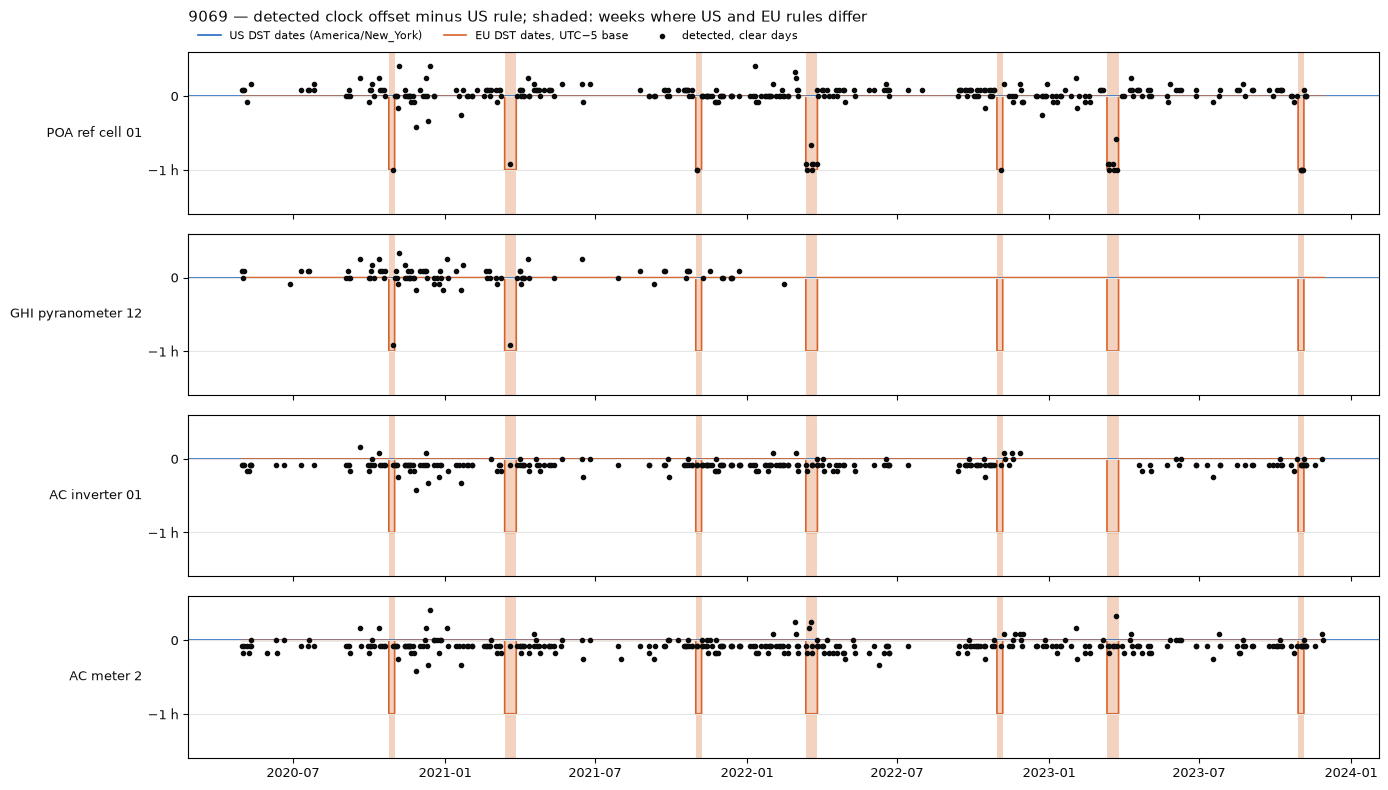

In [8]:
days = pd.date_range("2020-05-01", "2023-11-30", freq="D")
us = pd.Series(ta.expected_offset_h(days, "America/New_York").values, index=days)
eu = pd.Series(ta.expected_offset_h(days, ta.EU_DST_UTC5).values, index=days)
windows = [(a, b) for a, b in ta.rule_windows(range(2020, 2024)) if a >= days[0]]
fig = clock_offset_plot(
    offsets, base=("US DST dates (America/New_York)", us), other=("EU DST dates, UTC−5 base", eu),
    windows=windows,
    title="9069 — detected clock offset minus US rule; shaded: weeks where US and EU rules differ",
)
fig.savefig("reports/figures/9069_clock_offset.png", dpi=130, bbox_inches="tight")

**Acceptance test of the conversion.** The two rules give different answers only in the weeks between the US and EU switch dates (2 weeks in spring, 1 week in autumn). In those weeks, the lag between each channel and the reference cell is measured before conversion (raw labels) and after conversion to UTC with the per-file rules (`clock.rules` in the config). Pass = lag 0 after conversion in every window. Module temperature lags irradiance by 5–35 min because of thermal inertia; for it, the test is "same lag as in the control week", not "lag 0".

In [9]:
def to_utc_series(s, file):
    """Series on naive labels -> Series on UTC, with the clock rule of its file (config)."""
    out = s.copy()
    out.index = ta.to_utc(s.index, clk["rules"][file])
    return out[out.index.notna()]  # drops the skipped / repeated hour at a switch (night)


ref_utc = to_utc_series(ref, "irradiance")
others = {"AC inverter 01": (inv01, "electrical_ac"),
          "AC meter 2": (meter2, "meter"),
          "T module tc 01": (tmod, "environment")}
others_utc = {name: to_utc_series(s, file) for name, (s, file) in others.items()}

# Each window where the rules differ (from the plot cell), plus a control week before it
# (both rules agree there, so any lag in it is physical, not a clock effect).
checks = []
for a, b in windows:
    label = f"{a:%Y-%m-%d} to {b:%m-%d}"
    checks += [(label, "rules differ", a, b),
               (label, "control (week before)", a - pd.Timedelta(days=7), a - pd.Timedelta(days=1))]

rows = []
for label, kind, a, b in checks:
    end = b + pd.Timedelta("23h55min")
    # Same local days in UTC: shift by 5 h (exact to within the 1 h that is being tested).
    a_utc, end_utc = [(t + pd.Timedelta(hours=5)).tz_localize("UTC") for t in (a, end)]
    for name, (s, _) in others.items():
        lag_raw, _ = ta.lag_h(ref, s, a, end)
        lag_utc, r_utc = ta.lag_h(ref_utc, others_utc[name], a_utc, end_utc)
        rows.append({"window": label, "kind": kind, "channel": name,
                     "lag_raw_h": lag_raw, "lag_utc_h": lag_utc, "r": round(r_utc, 2)})
lags = pd.DataFrame(rows)
# NaN = no usable data in the window (inverter 01 reports 0 kW from late Feb to mid-Apr 2023).
lags.pivot_table(index=["window", "kind"], columns="channel",
                 values=["lag_raw_h", "lag_utc_h"], sort=False, dropna=False).round(2)

lag_raw_h             \
channel                                   AC inverter 01 AC meter 2   
window              kind                                              
2020-10-25 to 10-31 rules differ                    1.00        1.0   
                    control (week before)          -0.08        0.0   
2021-03-14 to 03-27 rules differ                    1.00        1.0   
                    control (week before)           0.00        0.0   
2021-10-31 to 11-06 rules differ                    1.00        1.0   
                    control (week before)           0.00        0.0   
2022-03-13 to 03-26 rules differ                    1.00        1.0   
                    control (week before)           0.00        0.0   
2022-10-30 to 11-05 rules differ                    1.00        1.0   
                    control (week before)           0.00        0.0   
2023-03-12 to 03-25 rules differ                     NaN        1.0   
                    control (week before)            NaN        0.0   
2023-10-29 to 11-04 rules differ                    1.00        1.0   
                    control (week before)           0.00        0.0   

                                                              lag_utc_h  \
channel                                   T module tc 01 AC inverter 01   
window              kind                                                  
2020-10-25 to 10-31 rules differ                    0.08           0.00   
                    control (week before)           0.08          -0.08   
2021-03-14 to 03-27 rules differ                    0.08           0.00   
                    control (week before)           0.50           0.00   
2021-10-31 to 11-06 rules differ                    0.17           0.00   
                    control (week before)           0.25           0.00   
2022-03-13 to 03-26 rules differ                    0.58           0.00   
                    control (week before)           0.08           0.00   
2022-10-30 to 11-05 rules differ                    0.08           0.00   
                    control (week before)           0.58           0.00   
2023-03-12 to 03-25 rules differ                    0.50            NaN   
                    control (week before)           0.58            NaN   
2023-10-29 to 11-04 rules differ                    0.58           0.00   
                    control (week before)           0.17           0.00   

                                                                     
channel                                   AC meter 2 T module tc 01  
window              kind                                             
2020-10-25 to 10-31 rules differ                 0.0           0.08  
                    control (week before)        0.0           0.08  
2021-03-14 to 03-27 rules differ                 0.0           0.08  
                    control (week before)        0.0           0.50  
2021-10-31 to 11-06 rules differ                 0.0           0.17  
                    control (week before)        0.0           0.25  
2022-03-13 to 03-26 rules differ                 0.0           0.58  
                    control (week before)        0.0           0.08  
2022-10-30 to 11-05 rules differ                 0.0           0.08  
                    control (week before)        0.0           0.58  
2023-03-12 to 03-25 rules differ                 0.0           0.50  
                    control (week before)        0.0           0.58  
2023-10-29 to 11-04 rules differ                 0.0           0.58  
                    control (week before)        0.0           0.17

### Observations — clock

- **The files do not share one clock.** All of them run at UTC−5 in winter and UTC−4 in summer, but:
  - **irradiance** (reference cell 01: 315 clear days, GHI: 93) switches on **EU dates** (last Sunday of March / October): 0 clear days contradict the EU rule, 23 (cell) contradict the US rule — all of them inside the shaded weeks;
  - **electrical_ac** (inverter 01: 244 clear days) and **meter** (meter 2: 328) switch on **US dates**: 0 contradict the US rule, 14 / 23 contradict the EU rule.
- **Environment** (module temperature, thermocouple 01) has the same lag to the reference cell inside the shaded weeks as in the control week before (5–35 min, thermal inertia), i.e. no 1 h jump: it runs on the irradiance clock. Inverter heatsink temperatures correlate too weakly with irradiance (r 0.3–0.45) to tell; they are marked unverified in the config and not used until checked.
- **Effect if ignored:** about 3 weeks a year (2 in spring, 1 in autumn) power would be shifted by 1 h against irradiance and module temperature — wrong PR on morning/evening hours and false anomalies.
- **Decision:** convert each file to UTC with its own rule (`clock.rules` in the config, `src/timealign.to_utc`). The skipped / repeated hour at each switch becomes NaT; it is always at night.
- **Acceptance test passed:** AC inverter 01 and meter 2 lag the reference cell by +1.0 h in every window before conversion and by 0.0 h after; in control weeks 0.0 both ways. Module temperature lag is unchanged by the conversion.
- The detected AC offset is systematically 5–10 min earlier than the irradiance offset (scatter just below 0 in the AC panels). Possible causes: interval labelling (start vs end of the 5-min interval) or the shape of the AC curve (clipping, inverter start-up). To check with the clear-day profiles in section 3.
- **Inverter 01 reports exactly 0 kW from late February to mid-April 2023** (~8 weeks) — a downtime candidate for Phase 3.
- The night-time jumps of the timestamp axis (1 h steps at 03:00 on US spring dates and at 21:00 before EU autumn dates, in every file) do not match the content of the files and are not used. They are probably an artefact of how the dataset was assembled.